# Structured Products Pricing

This notebook studies the **delta-hedging** of a short call option. A trader sells a call, then hedges it by holding the right number of shares, rebalanced at discrete dates. We simulate many possible price paths of the underlying (geometric Brownian motion, see `src/paths.py`), replay the hedge on each path (`src/hedging.py`), and look at what is left at maturity: the hedging P&L.

The key question: **if the hedge is meant to replicate the option, why is the P&L not zero?** We will see that it depends on how often we rebalance, on the volatility used to price and hedge versus the real one, and on transaction costs.

### Section 0 : Setup

In [36]:
import sys
from pathlib import Path
sys.path.append(str(Path.cwd().parent / 'src'))

import numpy as np
import matplotlib.pyplot as plt
import black_scholes as bs
import paths as ps
import hedging as hg

SEED = 42
SEED_PLOT = 47 # illustrative seed, 7 paths only: no statistical conclusion
N_PATHS = 40_000
N_PATHS_PLOT = 7
N_STEPS_DAILY = 252 # number of trading days in a year
SOME_N_STEPS = [4, 12, 25, 50, 100, 200, 400] # several number of steps for last test (or when needed)
N_STEPS_PLOT = 12

R = 0.05
T = 1.0
K = 100
SIGMA = 0.2
S0 = 100

### Section 1 : Hedging

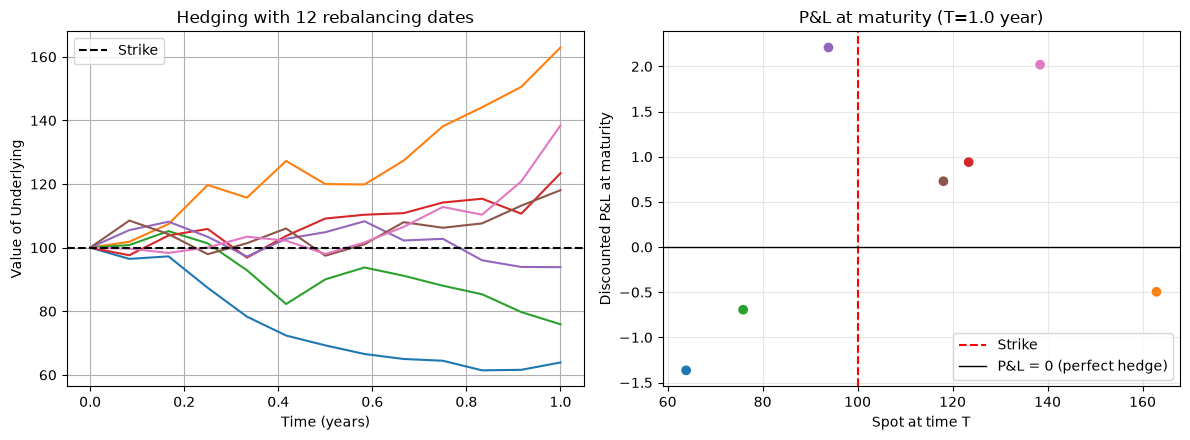

In [33]:
n_steps = N_STEPS_PLOT
n_paths = N_PATHS_PLOT

S = ps.simulate_gbm_paths(S0=S0, T=T, mu=R, sigma=SIGMA, n_steps=n_steps, n_paths=n_paths, seed=SEED_PLOT) #paths
pnl = hg.delta_hedge_pnl(S, K, T, R, sigma_impl=SIGMA) # final pnl
pnl_disc = pnl * np.exp(-R*T) # discounted pnl

t = np.linspace(0, T, n_steps + 1) # rebalancing dates
S_T = S[:, -1] # spot at maturity

colors = plt.cm.tab10(np.arange(n_paths))     # 7 diffrent colors

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.5))

# left: simulated paths (one color per path)
for i in range(n_paths):
    ax1.plot(t, S[i], color=colors[i])
ax1.axhline(K, color="black", linestyle="--", label="Strike")
ax1.set_xlabel("Time (years)")
ax1.set_ylabel("Value of Underlying")
ax1.set_title(f"Hedging with {n_steps} rebalancing dates")
ax1.legend()
ax1.grid(True)

# right: final P&L of each path (same color as on the left)
ax2.scatter(S_T, pnl_disc, c=colors)
ax2.axvline(K, color="red", linestyle="--", label="Strike")
ax2.axhline(0, color="black", linewidth=1, label="P&L = 0 (perfect hedge)")
ax2.set_xlabel("Spot at time T")
ax2.set_ylabel("Discounted P&L at maturity")
ax2.set_title(f"P&L at maturity (T={T} year)")
ax2.legend()
ax2.grid(alpha=0.3)

fig.tight_layout()
plt.savefig("../docs/hedge_paths.png", dpi=150, bbox_inches="tight")
plt.show()

**Reading the figure.** On the left, 7 simulated paths of the underlying over one year, with 12 rebalancing dates; the dashed line is the strike. On the right, each point is the final P&L of the hedge on the corresponding path (same color), plotted against the spot at maturity.

A perfect hedge would put every point on the line P&L = 0. Here the points are scattered around it: this is the **discrete rebalancing error**, because the delta is only adjusted 12 times instead of continuously. Note also that the P&L shows no clear link with the final spot: the hedge absorbs the movement of the underlying, whether the call ends in or out of the money.

These are only 7 illustrative paths (the seed was chosen for readability): the distribution of the P&L over many paths is studied in the next section.

### Section 2 : P&L

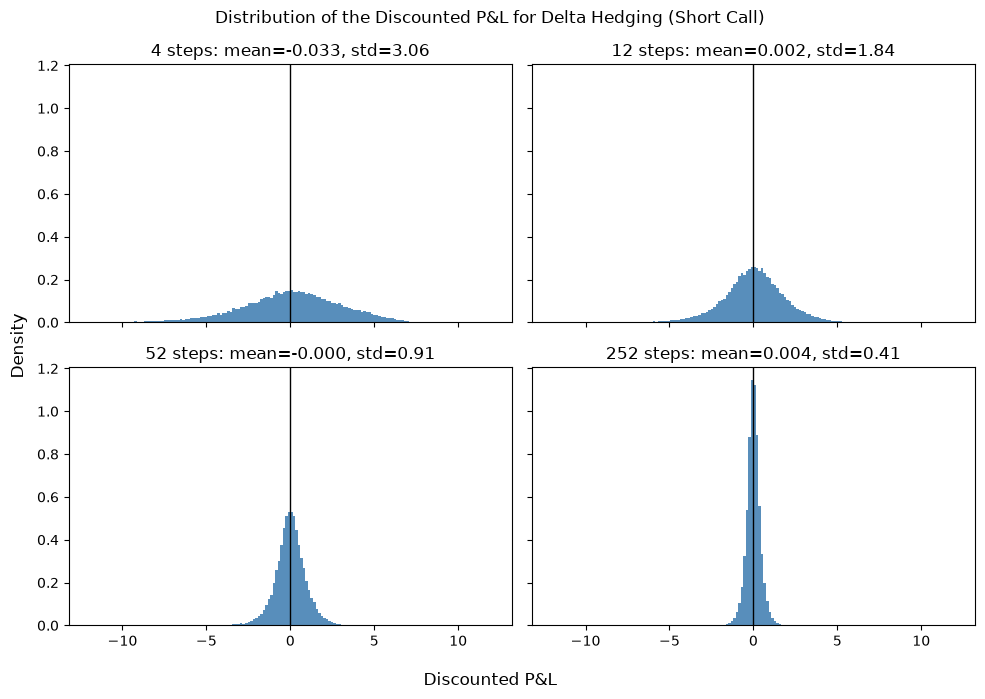

In [34]:
n_steps_list = [4, 12, 52, 252]

# Bins with same abscissa
bins = np.linspace(-12, 12, 161)

fig, axes = plt.subplots(2, 2, sharex=True, sharey=True, figsize=(10, 7))

for i, n in enumerate(n_steps_list):
    S = ps.simulate_gbm_paths(S0=S0, T=T, mu=R, sigma=SIGMA, n_steps=n, n_paths=N_PATHS, seed=SEED)
    pnl_disc = hg.delta_hedge_pnl(S, K, T, R, sigma_impl=SIGMA) * np.exp(-R * T)

    ax = axes.flat[i]
    ax.hist(pnl_disc, bins=bins, density=True, color="steelblue", alpha=0.9)
    ax.axvline(0, color="black", linewidth=1)

    m, s = pnl_disc.mean(), pnl_disc.std(ddof=1)
    ax.set_title(f"{n} steps: mean={m:.3f}, std={s:.2f}")

fig.suptitle("Distribution of the Discounted P&L for Delta Hedging (Short Call)")
fig.supxlabel("Discounted P&L")
fig.supylabel("Density")

plt.tight_layout()
plt.savefig("../docs/hedge_pnl_distribution.png", dpi=150, bbox_inches="tight")
plt.show()

**Reading the figure.** Each panel shows the distribution of the discounted final P&L over 40,000 simulated paths, for an increasing number of rebalancing dates (same x-axis in all panels).

- **The mean is compatible with 0 in every panel** (|mean| ≤ 0.03, i.e. well below the spread of the P&L). This is the replication property: when the real volatility equals the one used to price and hedge, the hedge is correct on average, whatever the rebalancing frequency.
- **The dispersion shrinks as we rebalance more often**: the standard deviation goes from 3.06 (4 dates) to 0.41 (252 dates), a ratio of about 7.5, close to the theoretical √(252/4) ≈ 7.9. This is the 1/√n decay of the replication error, which we check formally on a log-log scale below.

Even with daily rebalancing (252 dates), the hedge is not perfect: the standard deviation of the P&L is still about 4% of the option premium (10.45).

### Section 3 : log-log

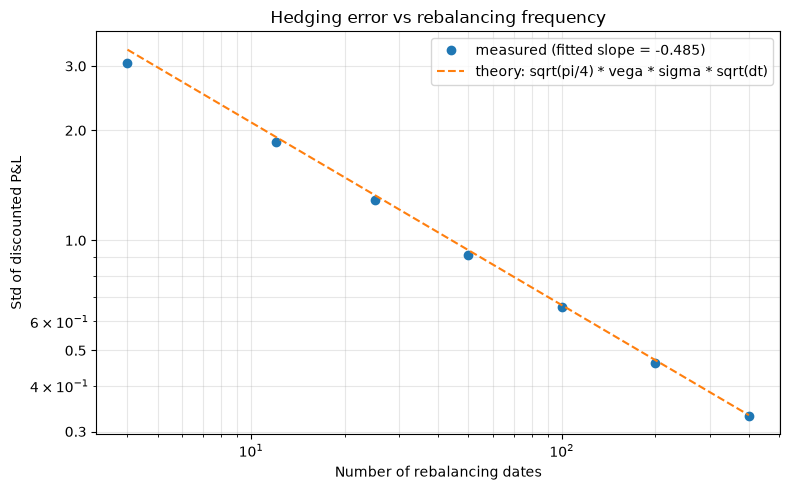

In [39]:
n_arr = np.array(SOME_N_STEPS)
stds = np.zeros(len(n_arr))

for i, n in enumerate(n_arr):
    S = ps.simulate_gbm_paths(S0=S0, T=T, mu=R, sigma=SIGMA, n_steps=n, n_paths=N_PATHS // 4, seed=SEED)
    pnl_disc = hg.delta_hedge_pnl(S, K, T, R, sigma_impl=SIGMA) * np.exp(-R * T)
    stds[i] = pnl_disc.std(ddof=1)

vega = bs.bs_vega(S0, K, T, R, SIGMA)
std_theory = np.sqrt(np.pi / 4) * vega * SIGMA * np.sqrt(T / n_arr)
slope, _ = np.polyfit(np.log(n_arr), np.log(stds), 1)

fig, ax = plt.subplots(figsize=(8, 5))
ax.loglog(n_arr, stds, "o", label=f"measured (fitted slope = {slope:.3f})")
ax.loglog(n_arr, std_theory, "--", label="theory: sqrt(pi/4) * vega * sigma * sqrt(dt)")
ax.set_yticks([0.3, 0.5, 1, 2, 3])
ax.get_yaxis().set_major_formatter(plt.ScalarFormatter())
ax.set_xlabel("Number of rebalancing dates")
ax.set_ylabel("Std of discounted P&L")
ax.set_title("Hedging error vs rebalancing frequency")
ax.legend()
ax.grid(alpha=0.3, which="both")
plt.tight_layout()
plt.savefig("../docs/hedge_std_loglog.png", dpi=150, bbox_inches="tight")
plt.show()

**Reading the figure.** Each point is the standard deviation of the discounted P&L (10,000 simulated paths) for a given number of rebalancing dates, on a log-log scale. The dashed line is the asymptotic theory for the discrete-hedging error: std ≈ √(π/4) · vega · σ · √dt.

- **The points follow a straight line of slope ≈ −0.49** (fitted: −0.485), which is the signature of a replication error decaying as 1/√n: rebalancing 4 times more often divides the error by about 2.
- **Measured values agree with the theoretical line**, especially for 50 dates and more. For very few dates (4 to 12), the measured std is slightly below the theory, which is expected since the formula is an asymptotic result valid when the number of dates is large.
- **The error never reaches zero**: halving the error costs four times as many rebalancing dates, and each rebalancing has a cost, which is the topic of the last section.